In [2]:
# A previsão trata a não convergência como ruído; o treino usa apenas o limiar de densidade.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from IPython.display import display


RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent


dataset = pd.read_csv(
    RAIZ
    / "datasets"
    / "dataset_experimental.csv"
)


COLUNAS_ML = [
    "taxa_requisicoes",
    "latencia_ms",
    "latencia_disponivel"
]

COLUNAS_CONTINUAS = [
    "taxa_requisicoes",
    "latencia_ms"
]


X_treino = dataset.loc[
    dataset["split"] == "treino",
    COLUNAS_ML
].copy()

X_validacao = dataset.loc[
    dataset["split"] == "validacao",
    COLUNAS_ML
].copy()

X_teste = dataset.loc[
    dataset["split"] == "teste",
    COLUNAS_ML
].copy()

In [3]:
mediana_latencia = (
    X_treino["latencia_ms"].median()
)

for X in [
    X_treino,
    X_validacao,
    X_teste
]:
    X["latencia_ms"] = (
        X["latencia_ms"]
        .fillna(mediana_latencia)
    )


print(
    "Mediana:",
    round(mediana_latencia, 4)
)

Mediana: 2.4758


In [4]:
scaler = StandardScaler()

scaler.fit(
    X_treino[
        COLUNAS_CONTINUAS
    ]
)


def transformar(X):

    resultado = X.copy()

    resultado[
        COLUNAS_CONTINUAS
    ] = scaler.transform(
        X[
            COLUNAS_CONTINUAS
        ]
    )

    return resultado


X_treino_std = transformar(
    X_treino
)

X_validacao_std = transformar(
    X_validacao
)

X_teste_std = transformar(
    X_teste
)

In [5]:
dados_treino = (
    X_treino_std
    .to_numpy(dtype=float)
)

dados_validacao = (
    X_validacao_std
    .to_numpy(dtype=float)
)

dados_teste = (
    X_teste_std
    .to_numpy(dtype=float)
)

print(dados_treino.shape)

(1080, 3)


In [6]:
def densidade_gaussiana(
    ponto,
    dados,
    sigma
):
    diferencas = (
        dados - ponto
    )

    distancia_quadrada = np.sum(
        diferencas ** 2,
        axis=1
    )

    pesos = np.exp(
        -distancia_quadrada
        / (2 * sigma ** 2)
    )

    dimensoes = dados.shape[1]

    normalizador = (
        len(dados)
        * (np.sqrt(2 * np.pi) * sigma)
        ** dimensoes
    )

    return (
        pesos.sum()
        / normalizador
    )

In [7]:
def encontrar_atrator(
    ponto,
    dados,
    sigma,
    tolerancia=1e-4,
    max_iteracoes=100
):
    atual = ponto.copy()

    for numero_iteracao in range(
        max_iteracoes
    ):

        diferencas = (
            dados - atual
        )

        distancia_quadrada = np.sum(
            diferencas ** 2,
            axis=1
        )

        pesos = np.exp(
            -distancia_quadrada
            / (2 * sigma ** 2)
        )

        soma_pesos = pesos.sum()

        if soma_pesos == 0:
            break

        novo = (
            pesos[:, None] * dados
        ).sum(axis=0) / soma_pesos

        deslocamento = np.linalg.norm(
            novo - atual
        )

        atual = novo

        if deslocamento < tolerancia:

            densidade = (
                densidade_gaussiana(
                    atual,
                    dados,
                    sigma
                )
            )

            return (
                atual,
                densidade,
                numero_iteracao + 1,
                True
            )

    densidade = densidade_gaussiana(
        atual,
        dados,
        sigma
    )

    return (
        atual,
        densidade,
        max_iteracoes,
        False
    )

In [8]:
def calcular_atratores(
    dados,
    sigma
):
    atratores = []
    densidades = []
    iteracoes = []
    convergiu = []

    for ponto in dados:

        (
            atrator,
            densidade,
            numero_iteracoes,
            sucesso
        ) = encontrar_atrator(
            ponto,
            dados,
            sigma
        )

        atratores.append(
            atrator
        )

        densidades.append(
            densidade
        )

        iteracoes.append(
            numero_iteracoes
        )

        convergiu.append(
            sucesso
        )

    return (
        np.array(atratores),
        np.array(densidades),
        np.array(iteracoes),
        np.array(convergiu)
    )

In [9]:
TOLERANCIA_ATRATOR = 0.05

In [10]:
def agrupar_atratores(
    atratores,
    tolerancia=0.05
):
    quantidade = len(atratores)

    pai = list(
        range(quantidade)
    )

    def encontrar(x):

        while pai[x] != x:

            pai[x] = pai[
                pai[x]
            ]

            x = pai[x]

        return x

    def unir(a, b):

        raiz_a = encontrar(a)
        raiz_b = encontrar(b)

        if raiz_a != raiz_b:
            pai[raiz_b] = raiz_a


    for i in range(quantidade):

        distancias = np.linalg.norm(
            atratores[i + 1:]
            - atratores[i],
            axis=1
        )

        proximos = np.where(
            distancias <= tolerancia
        )[0]

        for indice in proximos:

            j = (
                i
                + 1
                + indice
            )

            unir(i, j)


    raizes = [
        encontrar(i)
        for i in range(quantidade)
    ]

    mapa = {}

    labels = np.zeros(
        quantidade,
        dtype=int
    )

    proximo_cluster = 0

    for i, raiz in enumerate(raizes):

        if raiz not in mapa:

            mapa[raiz] = (
                proximo_cluster
            )

            proximo_cluster += 1

        labels[i] = mapa[raiz]

    return labels

In [11]:
def executar_denclue(
    dados,
    sigma,
    xi=0.0,
    tolerancia_atrator=0.05
):
    (
        atratores,
        densidades,
        iteracoes,
        convergiu
    ) = calcular_atratores(
        dados,
        sigma
    )

    labels = np.full(
        len(dados),
        -1,
        dtype=int
    )

    validos = (
        densidades >= xi
    )

    if validos.sum() > 0:

        labels_validos = (
            agrupar_atratores(
                atratores[validos],
                tolerancia_atrator
            )
        )

        labels[
            validos
        ] = labels_validos

    return {
        "labels": labels,
        "atratores": atratores,
        "densidades": densidades,
        "iteracoes": iteracoes,
        "convergiu": convergiu
    }

In [12]:
teste_denclue = executar_denclue(
    dados_treino,
    sigma=0.5
)

labels_teste = (
    teste_denclue["labels"]
)

print(
    "Clusters:",
    len(
        set(labels_teste)
        - {-1}
    )
)

print(
    "Convergência:",
    round(
        teste_denclue[
            "convergiu"
        ].mean() * 100,
        2
    ),
    "%"
)

print(
    "Iterações médias:",
    round(
        teste_denclue[
            "iteracoes"
        ].mean(),
        2
    )
)

Clusters: 2
Convergência: 100.0 %
Iterações médias: 25.3


In [13]:
SIGMAS = [
    0.15,
    0.25,
    0.35,
    0.50,
    0.75,
    1.00
]

In [14]:
resultados_sigma = []

labels_por_sigma = {}


for sigma in SIGMAS:

    print(
        "Executando sigma:",
        sigma
    )

    resultado = executar_denclue(
        dados_treino,
        sigma=sigma,
        xi=0.0
    )

    labels = resultado[
        "labels"
    ]

    labels_por_sigma[
        sigma
    ] = labels

    clusters_reais = sorted(
        set(labels) - {-1}
    )

    quantidade_clusters = len(
        clusters_reais
    )

    percentual_ruido = (
        (labels == -1).mean()
        * 100
    )

    if (
        quantidade_clusters >= 2
        and quantidade_clusters
        < len(dados_treino)
    ):

        silhouette = (
            silhouette_score(
                dados_treino[
                    labels != -1
                ],
                labels[
                    labels != -1
                ]
            )
        )

    else:
        silhouette = np.nan


    resultados_sigma.append({
        "sigma": sigma,
        "clusters": quantidade_clusters,
        "silhouette": silhouette,
        "ruido_percentual":
            percentual_ruido,
        "iteracoes_media":
            resultado[
                "iteracoes"
            ].mean(),
        "convergencia_percentual":
            resultado[
                "convergiu"
            ].mean() * 100
    })

Executando sigma: 0.15
Executando sigma: 0.25
Executando sigma: 0.35
Executando sigma: 0.5
Executando sigma: 0.75
Executando sigma: 1.0


In [15]:
tabela_sigma = pd.DataFrame(
    resultados_sigma
)

display(
    tabela_sigma.round(4)
)

,sigma,clusters,silhouette,ruido_percentual,iteracoes_media,convergencia_percentual
0,0.15,31,0.2808,0.0,39.8741,90.5556
1,0.25,13,0.2906,0.0,35.4093,100.0000
2,0.35,8,0.2503,0.0,28.7713,100.0000
3,0.50,2,0.5084,0.0,25.3019,100.0000
4,0.75,1,NaN,0.0,16.0944,100.0000
5,1.00,1,NaN,0.0,11.5148,100.0000


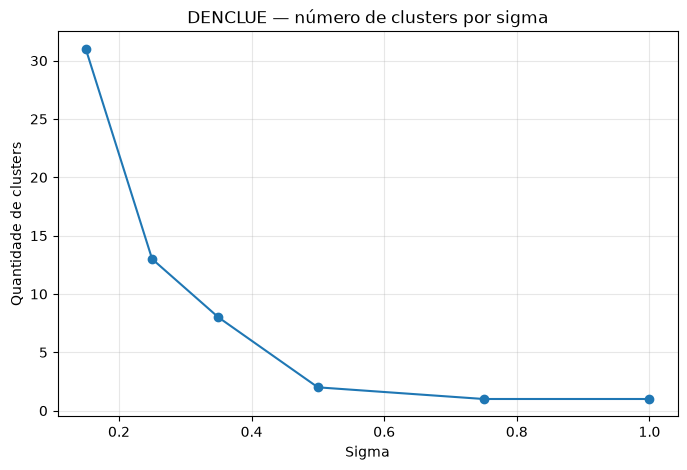

In [16]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    tabela_sigma["sigma"],
    tabela_sigma["clusters"],
    marker="o"
)

ax.set_title(
    "DENCLUE — número de clusters por sigma"
)

ax.set_xlabel(
    "Sigma"
)

ax.set_ylabel(
    "Quantidade de clusters"
)

ax.grid(alpha=0.3)

plt.show()

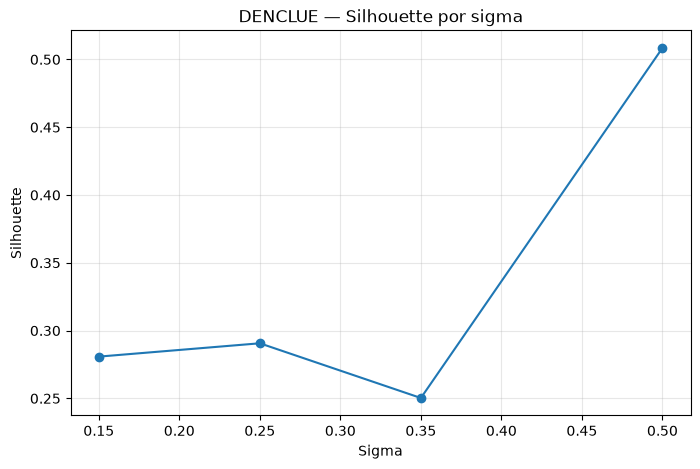

In [17]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    tabela_sigma["sigma"],
    tabela_sigma["silhouette"],
    marker="o"
)

ax.set_title(
    "DENCLUE — Silhouette por sigma"
)

ax.set_xlabel(
    "Sigma"
)

ax.set_ylabel(
    "Silhouette"
)

ax.grid(alpha=0.3)

plt.show()

In [18]:
SIGMAS_REFINADOS = [
    0.38,
    0.40,
    0.42,
    0.44,
    0.46,
    0.48,
    0.50,
    0.52,
    0.55
]

In [19]:
resultados_sigma_refinado = []

labels_sigma_refinado = {}


for sigma in SIGMAS_REFINADOS:

    print(
        "Executando sigma:",
        sigma
    )

    resultado = executar_denclue(
        dados_treino,
        sigma=sigma,
        xi=0.0
    )

    labels = resultado["labels"]

    labels_sigma_refinado[
        sigma
    ] = labels


    clusters_validos = sorted(
        set(labels) - {-1}
    )

    quantidade_clusters = len(
        clusters_validos
    )


    if (
        quantidade_clusters >= 2
        and quantidade_clusters
        < len(dados_treino)
    ):

        silhouette = silhouette_score(
            dados_treino[
                labels != -1
            ],
            labels[
                labels != -1
            ]
        )

    else:

        silhouette = np.nan


    resultados_sigma_refinado.append({
        "sigma": sigma,

        "clusters":
            quantidade_clusters,

        "silhouette":
            silhouette,

        "iteracoes_media":
            resultado[
                "iteracoes"
            ].mean(),

        "convergencia":
            resultado[
                "convergiu"
            ].mean() * 100
    })


tabela_sigma_refinado = pd.DataFrame(
    resultados_sigma_refinado
)

display(
    tabela_sigma_refinado.round(4)
)

Executando sigma: 0.38
Executando sigma: 0.4
Executando sigma: 0.42
Executando sigma: 0.44
Executando sigma: 0.46
Executando sigma: 0.48
Executando sigma: 0.5
Executando sigma: 0.52
Executando sigma: 0.55


,sigma,clusters,silhouette,iteracoes_media,convergencia
0,0.38,6,0.3151,30.9065,100.0
1,0.40,3,0.4912,34.5000,100.0
2,0.42,3,0.4912,29.7833,100.0
3,0.44,3,0.4912,28.2361,100.0
4,0.46,2,0.5084,27.1750,100.0
5,0.48,2,0.5084,26.2130,100.0
6,0.50,2,0.5084,25.3019,100.0
7,0.52,2,0.5084,24.4213,100.0
8,0.55,2,0.5084,23.1648,100.0


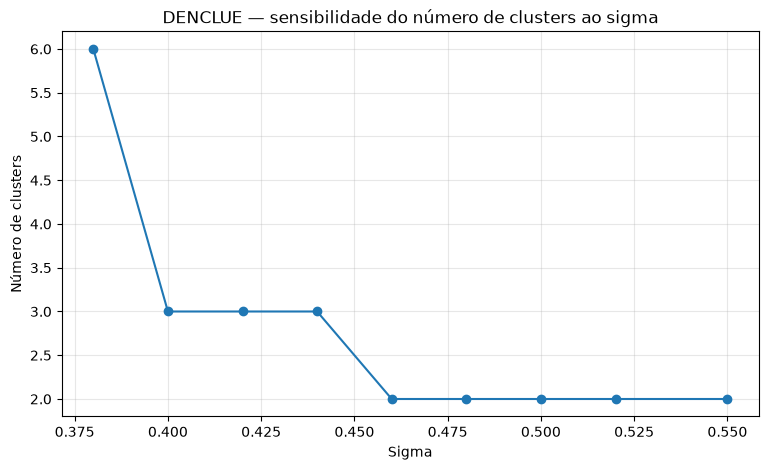

In [20]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    tabela_sigma_refinado["sigma"],
    tabela_sigma_refinado["clusters"],
    marker="o"
)

ax.set_title(
    "DENCLUE — sensibilidade do número de clusters ao sigma"
)

ax.set_xlabel("Sigma")

ax.set_ylabel(
    "Número de clusters"
)

ax.grid(alpha=0.3)

plt.show()

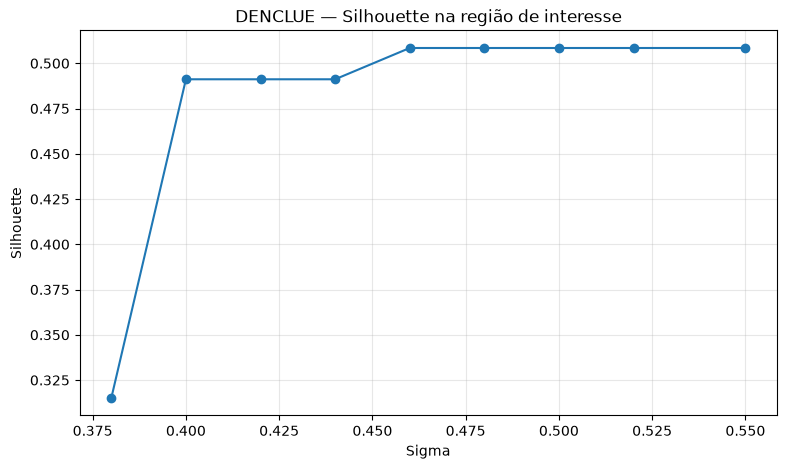

In [21]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    tabela_sigma_refinado["sigma"],
    tabela_sigma_refinado["silhouette"],
    marker="o"
)

ax.set_title(
    "DENCLUE — Silhouette na região de interesse"
)

ax.set_xlabel("Sigma")

ax.set_ylabel("Silhouette")

ax.grid(alpha=0.3)

plt.show()

In [43]:
SIGMA_ESCOLHIDO = 0.42

resultado_base = executar_denclue(
    dados_treino,
    sigma=SIGMA_ESCOLHIDO,
    xi=0.0
)

atratores_base = resultado_base[
    "atratores"
]

densidades_treino = resultado_base[
    "densidades"
]

resumo_densidades = (
    pd.Series(
        densidades_treino,
        name="densidade"
    )
    .describe(
        percentiles=[
            0.01,
            0.025,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

display(
    resumo_densidades
)

count    1080.000000
mean        0.173668
std         0.049645
min         0.002507
1%          0.034488
2.5%        0.034488
5%          0.034488
10%         0.034488
25%         0.191199
50%         0.191199
75%         0.191199
90%         0.191199
95%         0.191199
99%         0.191199
max         0.191199
Name: densidade, dtype: float64

In [44]:
print(
    "Densidades distintas:",
    len(
        np.unique(
            np.round(
                densidades_treino,
                8
            )
        )
    )
)

print(
    "Densidade mínima:",
    densidades_treino.min()
)

print(
    "Densidade máxima:",
    densidades_treino.max()
)

Densidades distintas: 4
Densidade mínima: 0.0025066597489559156
Densidade máxima: 0.19119873960751568


In [45]:
candidatos_xi = {
    "sem_limiar": 0.0,

    "p1": np.percentile(
        densidades_treino,
        1
    ),

    "p2_5": np.percentile(
        densidades_treino,
        2.5
    ),

    "p5": np.percentile(
        densidades_treino,
        5
    ),

    "p10": np.percentile(
        densidades_treino,
        10
    )
}

display(
    pd.DataFrame(
        candidatos_xi.items(),
        columns=[
            "configuracao",
            "xi"
        ]
    )
)

,configuracao,xi
0,sem_limiar,0.000000
1,p1,0.034488
2,p2_5,0.034488
3,p5,0.034488
4,p10,0.034488


In [46]:
resultados_xi = []

labels_por_xi = {}


for nome, xi in candidatos_xi.items():

    labels = np.full(
        len(dados_treino),
        -1,
        dtype=int
    )

    validos = (
        densidades_treino >= xi
    )

    if validos.sum() > 0:

        labels_validos = (
            agrupar_atratores(
                atratores_base[
                    validos
                ],
                tolerancia=
                    TOLERANCIA_ATRATOR
            )
        )

        labels[
            validos
        ] = labels_validos


    labels_por_xi[
        nome
    ] = labels


    clusters_validos = sorted(
        set(labels) - {-1}
    )

    numero_clusters = len(
        clusters_validos
    )

    percentual_ruido = (
        (labels == -1).mean()
        * 100
    )


    if (
        numero_clusters >= 2
        and validos.sum()
        > numero_clusters
    ):

        silhouette = (
            silhouette_score(
                dados_treino[
                    validos
                ],
                labels[
                    validos
                ]
            )
        )

    else:

        silhouette = np.nan


    resultados_xi.append({
        "configuracao": nome,
        "xi": xi,
        "clusters": numero_clusters,
        "ruido_percentual":
            percentual_ruido,
        "silhouette":
            silhouette,
        "pontos_validos":
            validos.sum()
    })


tabela_xi = pd.DataFrame(
    resultados_xi
)

display(
    tabela_xi.round(6)
)

,configuracao,xi,clusters,ruido_percentual,silhouette,pontos_validos
0,sem_limiar,0.000000,3,0.000000,0.491152,1080
1,p1,0.034488,2,1.018519,0.504240,1069
2,p2_5,0.034488,2,2.500000,0.502807,1053
3,p5,0.034488,2,4.629630,0.499306,1030
4,p10,0.034488,2,10.000000,0.508559,972


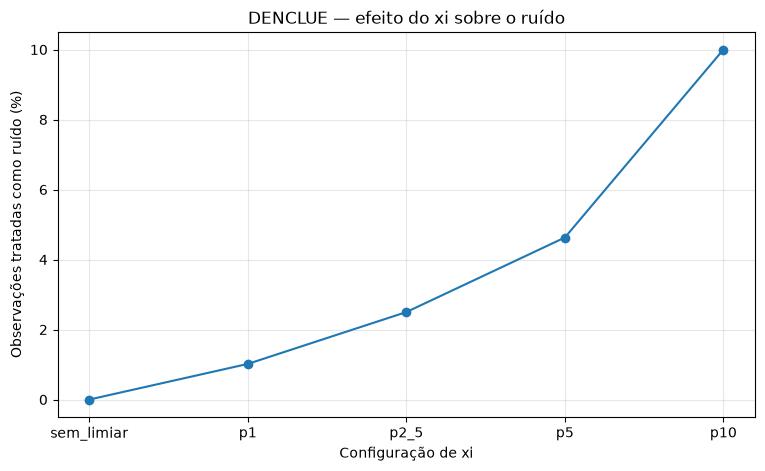

In [47]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    tabela_xi[
        "configuracao"
    ],
    tabela_xi[
        "ruido_percentual"
    ],
    marker="o"
)

ax.set_title(
    "DENCLUE — efeito do xi sobre o ruído"
)

ax.set_xlabel(
    "Configuração de xi"
)

ax.set_ylabel(
    "Observações tratadas como ruído (%)"
)

ax.grid(alpha=0.3)

plt.show()

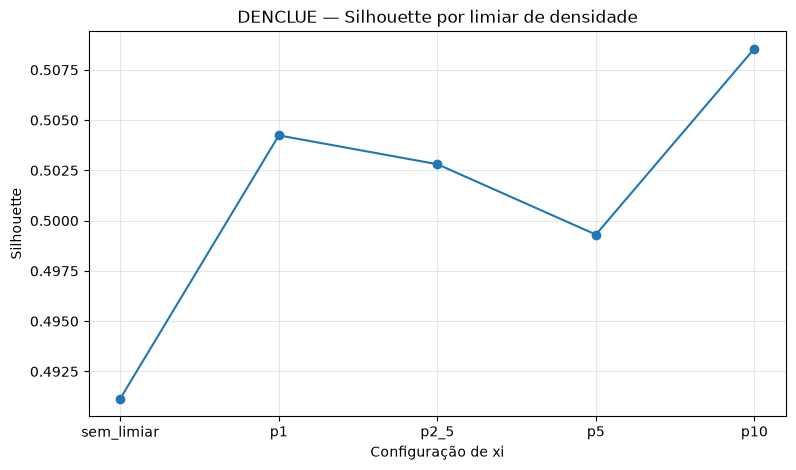

In [48]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    tabela_xi[
        "configuracao"
    ],
    tabela_xi[
        "silhouette"
    ],
    marker="o"
)

ax.set_title(
    "DENCLUE — Silhouette por limiar de densidade"
)

ax.set_xlabel(
    "Configuração de xi"
)

ax.set_ylabel(
    "Silhouette"
)

ax.grid(alpha=0.3)

plt.show()

In [49]:
resultado_base = executar_denclue(
    dados_treino,
    sigma=SIGMA_ESCOLHIDO,
    xi=0.0
)

atratores_base = resultado_base["atratores"]
densidades_treino = resultado_base["densidades"]

labels_base = agrupar_atratores(
    atratores_base,
    tolerancia=TOLERANCIA_ATRATOR
)

print(
    "Clusters antes do xi:",
    sorted(np.unique(labels_base))
)

Clusters antes do xi: [np.int64(0), np.int64(1), np.int64(2)]


In [50]:
resumo_atratores = []

for cluster in sorted(
    np.unique(labels_base)
):

    mascara = (
        labels_base == cluster
    )

    atrator_representante = (
        atratores_base[
            mascara
        ].mean(axis=0)
    )

    densidade_atrator = (
        densidade_gaussiana(
            atrator_representante,
            dados_treino,
            SIGMA_ESCOLHIDO
        )
    )

    resumo_atratores.append({
        "cluster": cluster,
        "quantidade": mascara.sum(),
        "percentual": (
            mascara.mean() * 100
        ),
        "densidade_atrator":
            densidade_atrator
    })


tabela_atratores = pd.DataFrame(
    resumo_atratores
)

display(
    tabela_atratores.sort_values(
        "densidade_atrator"
    ).round(8)
)

,cluster,quantidade,percentual,densidade_atrator
2,2,4,0.370370,0.002507
1,1,116,10.740741,0.034487
0,0,960,88.888889,0.191199


In [51]:
densidades_atratores = np.sort(
    tabela_atratores[
        "densidade_atrator"
    ].unique()
)

print(
    densidades_atratores
)

candidatos_xi_atrator = {
    "sem_limiar": 0.0
}

for i in range(
    len(densidades_atratores) - 1
):

    inferior = (
        densidades_atratores[i]
    )

    superior = (
        densidades_atratores[i + 1]
    )

    meio = (
        inferior + superior
    ) / 2

    candidatos_xi_atrator[
        f"entre_{i}_{i+1}"
    ] = meio


display(
    pd.DataFrame(
        candidatos_xi_atrator.items(),
        columns=[
            "configuracao",
            "xi"
        ]
    )
)

[0.00250666 0.0344875  0.19119874]


,configuracao,xi
0,sem_limiar,0.000000
1,entre_0_1,0.018497
2,entre_1_2,0.112843


In [52]:
resultados_xi_atrator = []


for nome, xi in (
    candidatos_xi_atrator.items()
):

    labels = labels_base.copy()

    clusters_removidos = []

    for _, linha in (
        tabela_atratores.iterrows()
    ):

        cluster = int(
            linha["cluster"]
        )

        densidade = (
            linha[
                "densidade_atrator"
            ]
        )

        if densidade < xi:

            labels[
                labels == cluster
            ] = -1

            clusters_removidos.append(
                cluster
            )


    validos = (
        labels != -1
    )

    clusters_restantes = (
        len(
            set(labels)
            - {-1}
        )
    )

    ruido = (
        (~validos).mean()
        * 100
    )


    if (
        clusters_restantes >= 2
        and validos.sum()
        > clusters_restantes
    ):

        silhouette = (
            silhouette_score(
                dados_treino[
                    validos
                ],
                labels[
                    validos
                ]
            )
        )

    else:

        silhouette = np.nan


    resultados_xi_atrator.append({
        "configuracao": nome,
        "xi": xi,
        "clusters":
            clusters_restantes,
        "ruido_percentual":
            ruido,
        "silhouette":
            silhouette,
        "clusters_removidos":
            str(
                clusters_removidos
            )
    })

In [53]:
tabela_xi_atrator = pd.DataFrame(
    resultados_xi_atrator
)

display(
    tabela_xi_atrator.round(6)
)

,configuracao,xi,clusters,ruido_percentual,silhouette,clusters_removidos
0,sem_limiar,0.000000,3,0.000000,0.491152,[]
1,entre_0_1,0.018497,2,0.370370,0.505234,[2]
2,entre_1_2,0.112843,1,11.111111,NaN,"[1, 2]"


In [54]:
SIGMA_DENCLUE = 0.42

densidades_ordenadas = np.sort(
    tabela_atratores[
        "densidade_atrator"
    ].to_numpy()
)

XI_DENCLUE = (
    densidades_ordenadas[0]
    + densidades_ordenadas[1]
) / 2


print(
    "Sigma:",
    SIGMA_DENCLUE
)

print(
    "Xi:",
    f"{XI_DENCLUE:.15f}"
)

Sigma: 0.42
Xi: 0.018497080747067


In [55]:
labels_treino_denclue = (
    labels_base.copy()
)
for _, linha in (
    tabela_atratores.iterrows()
):

    cluster = int(
        linha["cluster"]
    )

    densidade = (
        linha["densidade_atrator"]
    )

    if densidade < XI_DENCLUE:

        labels_treino_denclue[
            labels_treino_denclue
            == cluster
        ] = -1

contagem_treino_denclue = (
    pd.Series(
        labels_treino_denclue
    )
    .value_counts()
    .sort_index()
)

display(
    contagem_treino_denclue
)

-1      4
 0    960
 1    116
Name: count, dtype: int64

In [56]:
ids_clusters = np.array(
    sorted(
        set(
            labels_treino_denclue
        ) - {-1}
    )
)

representantes = []

for cluster in ids_clusters:

    mascara = (
        labels_treino_denclue
        == cluster
    )

    representante = (
        atratores_base[
            mascara
        ].mean(axis=0)
    )

    representantes.append(
        representante
    )


representantes = np.array(
    representantes
)


print(
    "Clusters sobreviventes:",
    ids_clusters
)

print(
    "Representantes:"
)

display(
    pd.DataFrame(
        representantes,
        index=ids_clusters,
        columns=COLUNAS_ML
    )
)

Clusters sobreviventes: [0 1]
Representantes:


,taxa_requisicoes,latencia_ms,latencia_disponivel
0,-0.593893,0.441846,0.990874
1,2.364644,0.172303,0.991470


In [57]:
def prever_denclue(
    dados_novos,
    dados_referencia,
    sigma,
    xi,
    representantes,
    ids_clusters
):

    previsoes = []
    densidades = []
    atratores = []

    for ponto in dados_novos:

        (
            atrator,
            densidade,
            iteracoes,
            convergiu
        ) = encontrar_atrator(
            ponto,
            dados_referencia,
            sigma
        )

        atratores.append(
            atrator
        )

        densidades.append(
            densidade
        )

        if (
            not convergiu
            or densidade < xi
        ):

            previsoes.append(-1)
            continue


        distancias = np.linalg.norm(
            representantes
            - atrator,
            axis=1
        )

        indice = np.argmin(
            distancias
        )

        previsoes.append(
            int(
                ids_clusters[
                    indice
                ]
            )
        )


    return (
        np.array(previsoes),
        np.array(densidades),
        np.array(atratores)
    )

In [58]:
(
    clusters_validacao_denclue,
    densidades_validacao,
    atratores_validacao
) = prever_denclue(
    dados_validacao,
    dados_treino,
    SIGMA_DENCLUE,
    XI_DENCLUE,
    representantes,
    ids_clusters
)
display(
    pd.Series(
        clusters_validacao_denclue
    )
    .value_counts()
    .sort_index()
    .rename("quantidade")
)

-1      4
 0    480
 1     56
Name: quantidade, dtype: int64

In [59]:
COLUNAS_AVALIACAO = [
    "label",
    "condicao",
    "nivel_carga",
    "manutencao_legitima",
    "janela_transicao",
    "seed",
    "ensaio",
    "janela"
]


avaliacao_validacao = dataset.loc[
    dataset["split"]
    == "validacao",
    COLUNAS_AVALIACAO
].copy()

resultado_validacao_denclue = (
    avaliacao_validacao.copy()
)

resultado_validacao_denclue[
    "cluster"
] = clusters_validacao_denclue

In [60]:
tabela_denclue_validacao = (
    pd.crosstab(
        resultado_validacao_denclue[
            "cluster"
        ],
        resultado_validacao_denclue[
            "label"
        ]
    )
)

display(
    tabela_denclue_validacao
)

label,0,1
cluster,,
-1,0,4
0,357,123
1,0,56


In [61]:
percentual_denclue = (
    pd.crosstab(
        resultado_validacao_denclue[
            "cluster"
        ],
        resultado_validacao_denclue[
            "label"
        ],
        normalize="index"
    )
    * 100
)

display(
    percentual_denclue.round(2)
)

label,0,1
cluster,,
-1,0.00,100.00
0,74.38,25.62
1,0.00,100.00


In [62]:
proporcao_ataque_denclue = (
    resultado_validacao_denclue
    .groupby("cluster")[
        "label"
    ]
    .mean()
)

display(
    (
        proporcao_ataque_denclue
        * 100
    )
    .round(2)
    .rename(
        "percentual_ataque"
    )
)

cluster
-1    100.00
 0     25.62
 1    100.00
Name: percentual_ataque, dtype: float64

In [63]:
MAPA_DENCLUE = {
    cluster:
        int(proporcao > 0.50)

    for cluster, proporcao
    in proporcao_ataque_denclue.items()
}

print(
    MAPA_DENCLUE
)

{-1: 1, 0: 0, 1: 1}


In [64]:
tabela_condicao_denclue = (
    pd.crosstab(
        resultado_validacao_denclue[
            "cluster"
        ],
        resultado_validacao_denclue[
            "condicao"
        ]
    )
)

display(
    tabela_condicao_denclue
)

condicao,carga_alta,carga_baixa,carga_media,manutencao,normal,recuperacao
cluster,,,,,,
-1,4,0,0,0,0,0
0,3,60,60,45,135,177
1,56,0,0,0,0,0


In [65]:
display(
    (
        pd.crosstab(
            resultado_validacao_denclue[
                "cluster"
            ],
            resultado_validacao_denclue[
                "condicao"
            ],
            normalize="index"
        )
        * 100
    ).round(2)
)

condicao,carga_alta,carga_baixa,carga_media,manutencao,normal,recuperacao
cluster,,,,,,
-1,100.00,0.0,0.0,0.00,0.00,0.00
0,0.62,12.5,12.5,9.38,28.12,36.88
1,100.00,0.0,0.0,0.00,0.00,0.00


In [66]:
avaliacao_teste = dataset.loc[
    dataset["split"] == "teste",
    COLUNAS_AVALIACAO
].copy()

In [67]:
(
    clusters_teste_denclue,
    densidades_teste,
    atratores_teste
) = prever_denclue(
    dados_teste,
    dados_treino,
    SIGMA_DENCLUE,
    XI_DENCLUE,
    representantes,
    ids_clusters
)

In [68]:
resultado_teste_denclue = (
    avaliacao_teste.copy()
)

resultado_teste_denclue[
    "cluster"
] = clusters_teste_denclue

resultado_teste_denclue[
    "previsao"
] = (
    resultado_teste_denclue[
        "cluster"
    ]
    .map(MAPA_DENCLUE)
)

display(
    resultado_teste_denclue[
        "cluster"
    ]
    .value_counts()
    .sort_index()
)

cluster
-1      3
 0    480
 1     57
Name: count, dtype: int64

In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


y_teste_denclue = (
    resultado_teste_denclue[
        "label"
    ]
)

pred_teste_denclue = (
    resultado_teste_denclue[
        "previsao"
    ]
)


metricas_denclue = {
    "acuracia": accuracy_score(
        y_teste_denclue,
        pred_teste_denclue
    ),

    "precisao": precision_score(
        y_teste_denclue,
        pred_teste_denclue,
        zero_division=0
    ),

    "recall": recall_score(
        y_teste_denclue,
        pred_teste_denclue
    ),

    "f1": f1_score(
        y_teste_denclue,
        pred_teste_denclue
    )
}


for nome, valor in (
    metricas_denclue.items()
):

    print(
        f"{nome}: {valor:.4f}"
    )

acuracia: 0.7722
precisao: 1.0000
recall: 0.3279
f1: 0.4938


In [70]:
matriz_denclue = confusion_matrix(
    y_teste_denclue,
    pred_teste_denclue
)

display(
    pd.DataFrame(
        matriz_denclue,

        index=[
            "Real legítimo",
            "Real ataque"
        ],

        columns=[
            "Previsto legítimo",
            "Previsto ataque"
        ]
    )
)

,Previsto legítimo,Previsto ataque
Real legítimo,357,0
Real ataque,123,60


In [71]:
tn, fp, fn, tp = (
    matriz_denclue.ravel()
)

especificidade = (
    tn / (tn + fp)
)

taxa_falso_alarme = (
    fp / (tn + fp)
)

taxa_ataques_perdidos = (
    fn / (tp + fn)
)


print(
    "Especificidade:",
    round(
        especificidade,
        4
    )
)

print(
    "Taxa falso alarme:",
    round(
        taxa_falso_alarme,
        4
    )
)

print(
    "Taxa ataques perdidos:",
    round(
        taxa_ataques_perdidos,
        4
    )
)

Especificidade: 1.0
Taxa falso alarme: 0.0
Taxa ataques perdidos: 0.6721


In [72]:
ataques_teste_denclue = (
    resultado_teste_denclue[
        resultado_teste_denclue[
            "label"
        ] == 1
    ]
    .copy()
)


recall_nivel_denclue = (
    ataques_teste_denclue
    .groupby(
        "nivel_carga"
    )
    .agg(
        total=("label", "size"),

        detectados=(
            "previsao",
            "sum"
        )
    )
)


recall_nivel_denclue[
    "recall"
] = (
    recall_nivel_denclue[
        "detectados"
    ]
    / recall_nivel_denclue[
        "total"
    ]
)


display(
    recall_nivel_denclue.round(4)
)

,total,detectados,recall
nivel_carga,,,
alta,63,60,0.9524
baixa,60,0,0.0000
media,60,0,0.0000


In [73]:
legitimos_denclue = (
    resultado_teste_denclue[
        resultado_teste_denclue[
            "label"
        ] == 0
    ]
    .copy()
)


legitimos_denclue[
    "falso_positivo"
] = (
    legitimos_denclue[
        "previsao"
    ] == 1
).astype(int)


falsos_denclue = (
    legitimos_denclue
    .groupby(
        "condicao"
    )
    .agg(
        total=("label", "size"),

        falsos_positivos=(
            "falso_positivo",
            "sum"
        )
    )
)


falsos_denclue[
    "taxa_falso_positivo"
] = (
    falsos_denclue[
        "falsos_positivos"
    ]
    / falsos_denclue[
        "total"
    ]
)


display(
    falsos_denclue.round(4)
)

,total,falsos_positivos,taxa_falso_positivo
condicao,,,
manutencao,45,0,0.0
normal,135,0,0.0
recuperacao,177,0,0.0


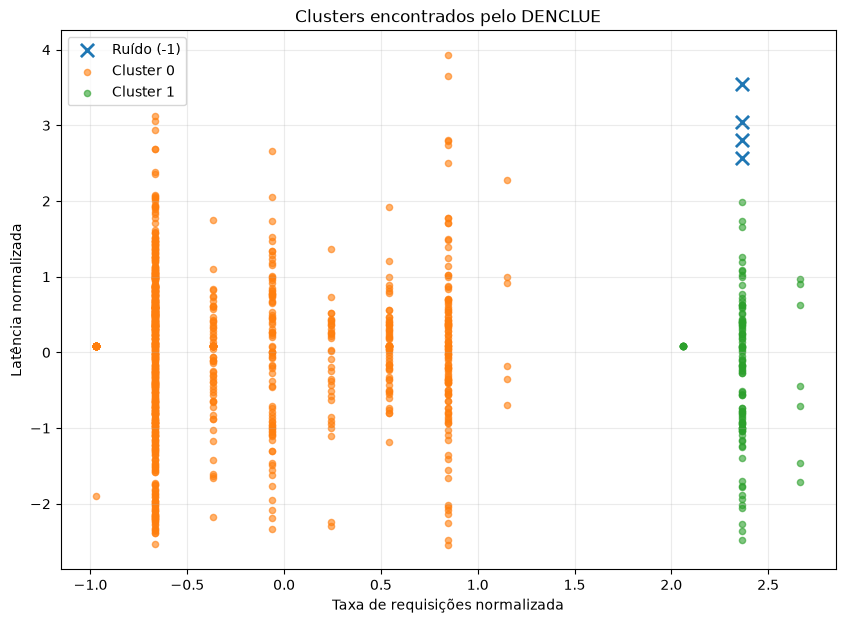

In [74]:
fig, ax = plt.subplots(
    figsize=(10, 7)
)

clusters_existentes = sorted(
    np.unique(labels_treino_denclue)
)

for cluster in clusters_existentes:

    mascara = (
        labels_treino_denclue
        == cluster
    )

    if cluster == -1:

        ax.scatter(
            X_treino_std.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_treino_std.loc[
                mascara,
                "latencia_ms"
            ],
            marker="x",
            s=90,
            linewidths=2,
            label="Ruído (-1)"
        )

    else:

        ax.scatter(
            X_treino_std.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_treino_std.loc[
                mascara,
                "latencia_ms"
            ],
            s=20,
            alpha=0.6,
            label=f"Cluster {cluster}"
        )


ax.set_title(
    "Clusters encontrados pelo DENCLUE"
)

ax.set_xlabel(
    "Taxa de requisições normalizada"
)

ax.set_ylabel(
    "Latência normalizada"
)

ax.legend()

ax.grid(
    alpha=0.25
)

plt.show()

In [75]:
atratores_centrais = []

for cluster in sorted(
    np.unique(labels_base)
):

    mascara = (
        labels_base == cluster
    )

    centro = (
        atratores_base[
            mascara
        ].mean(axis=0)
    )

    atratores_centrais.append({
        "cluster": cluster,
        "taxa_requisicoes":
            centro[0],
        "latencia_ms":
            centro[1],
        "latencia_disponivel":
            centro[2]
    })


atratores_centrais = pd.DataFrame(
    atratores_centrais
)

display(
    atratores_centrais.round(4)
)

,cluster,taxa_requisicoes,latencia_ms,latencia_disponivel
0,0,-0.5939,0.4418,0.9909
1,1,2.3646,0.1723,0.9915
2,2,2.3569,2.7549,1.0000


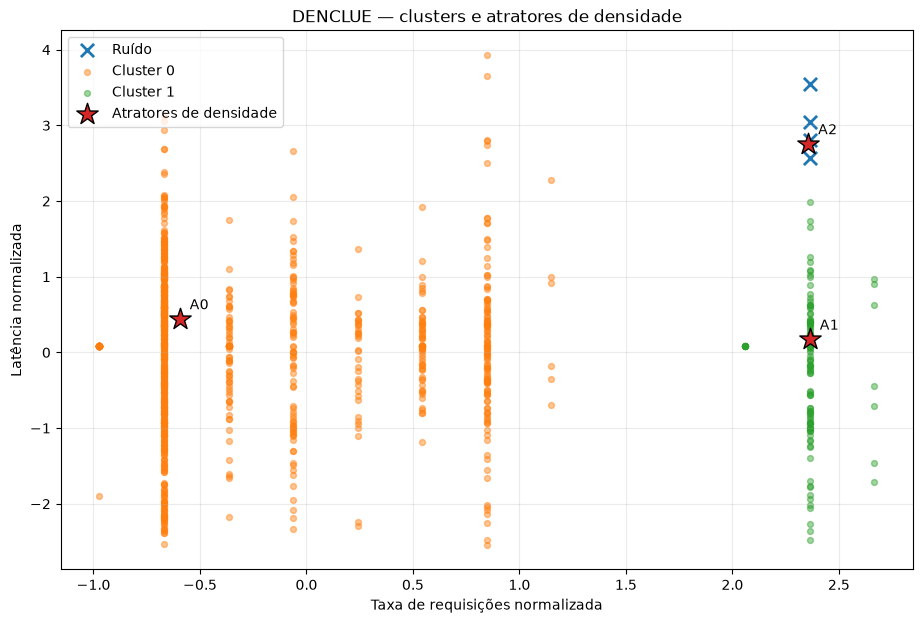

In [76]:
fig, ax = plt.subplots(
    figsize=(11, 7)
)


for cluster in sorted(
    np.unique(labels_treino_denclue)
):

    mascara = (
        labels_treino_denclue
        == cluster
    )

    if cluster == -1:

        ax.scatter(
            X_treino_std.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_treino_std.loc[
                mascara,
                "latencia_ms"
            ],
            marker="x",
            s=90,
            linewidths=2,
            label="Ruído"
        )

    else:

        ax.scatter(
            X_treino_std.loc[
                mascara,
                "taxa_requisicoes"
            ],
            X_treino_std.loc[
                mascara,
                "latencia_ms"
            ],
            s=18,
            alpha=0.45,
            label=f"Cluster {cluster}"
        )


ax.scatter(
    atratores_centrais[
        "taxa_requisicoes"
    ],
    atratores_centrais[
        "latencia_ms"
    ],
    marker="*",
    s=260,
    edgecolors="black",
    linewidths=1,
    label="Atratores de densidade"
)


for _, linha in (
    atratores_centrais.iterrows()
):

    ax.annotate(
        f"A{int(linha['cluster'])}",
        (
            linha[
                "taxa_requisicoes"
            ],
            linha[
                "latencia_ms"
            ]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=10
    )


ax.set_title(
    "DENCLUE — clusters e atratores de densidade"
)

ax.set_xlabel(
    "Taxa de requisições normalizada"
)

ax.set_ylabel(
    "Latência normalizada"
)

ax.legend()

ax.grid(alpha=0.25)

plt.show()

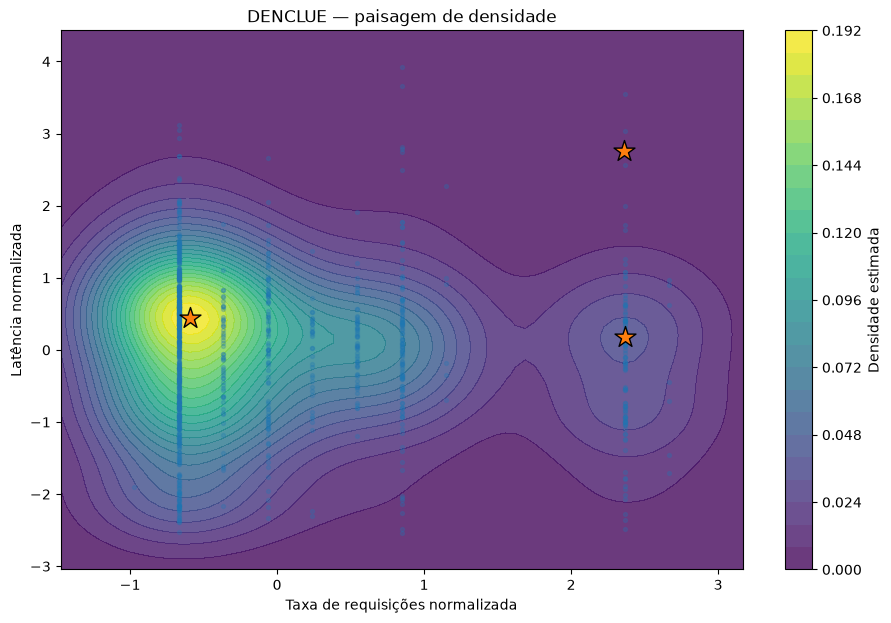

In [77]:
x_min = (
    X_treino_std[
        "taxa_requisicoes"
    ].min() - 0.5
)

x_max = (
    X_treino_std[
        "taxa_requisicoes"
    ].max() + 0.5
)

y_min = (
    X_treino_std[
        "latencia_ms"
    ].min() - 0.5
)

y_max = (
    X_treino_std[
        "latencia_ms"
    ].max() + 0.5
)

eixo_x = np.linspace(
    x_min,
    x_max,
    70
)

eixo_y = np.linspace(
    y_min,
    y_max,
    70
)

grade_x, grade_y = np.meshgrid(
    eixo_x,
    eixo_y
)

densidade_grade = np.zeros(
    grade_x.shape
)

for i in range(
    grade_x.shape[0]
):

    for j in range(
        grade_x.shape[1]
    ):

        ponto = np.array([
            grade_x[i, j],
            grade_y[i, j],
            1.0
        ])

        densidade_grade[
            i,
            j
        ] = densidade_gaussiana(
            ponto,
            dados_treino,
            SIGMA_DENCLUE
        )
fig, ax = plt.subplots(
    figsize=(11, 7)
)


contorno = ax.contourf(
    grade_x,
    grade_y,
    densidade_grade,
    levels=25,
    alpha=0.8
)


mascara_disponivel = (
    X_treino_std[
        "latencia_disponivel"
    ] == 1
)


ax.scatter(
    X_treino_std.loc[
        mascara_disponivel,
        "taxa_requisicoes"
    ],
    X_treino_std.loc[
        mascara_disponivel,
        "latencia_ms"
    ],
    s=8,
    alpha=0.25
)


ax.scatter(
    atratores_centrais[
        "taxa_requisicoes"
    ],
    atratores_centrais[
        "latencia_ms"
    ],
    marker="*",
    s=250,
    edgecolors="black",
    linewidths=1
)


fig.colorbar(
    contorno,
    ax=ax,
    label="Densidade estimada"
)


ax.set_title(
    "DENCLUE — paisagem de densidade"
)

ax.set_xlabel(
    "Taxa de requisições normalizada"
)

ax.set_ylabel(
    "Latência normalizada"
)

plt.show()

In [78]:
COLUNAS_AVALIACAO = [
    "label",
    "condicao",
    "nivel_carga",
    "manutencao_legitima",
    "janela_transicao",
    "seed",
    "ensaio",
    "janela"
]

avaliacao_treino = dataset.loc[
    dataset["split"] == "treino",
    COLUNAS_AVALIACAO
].copy()


resultado_treino_denclue = (
    avaliacao_treino.copy()
)

resultado_treino_denclue[
    "cluster"
] = labels_treino_denclue

In [79]:
composicao_denclue = pd.crosstab(
    resultado_treino_denclue[
        "cluster"
    ],
    resultado_treino_denclue[
        "condicao"
    ],
    normalize="index"
) * 100

display(
    composicao_denclue.round(2)
)

condicao,carga_alta,carga_baixa,carga_media,manutencao,normal,recuperacao
cluster,,,,,,
-1,100.00,0.0,0.0,0.00,0.00,0.00
0,0.62,12.5,12.5,9.38,28.12,36.88
1,100.00,0.0,0.0,0.00,0.00,0.00


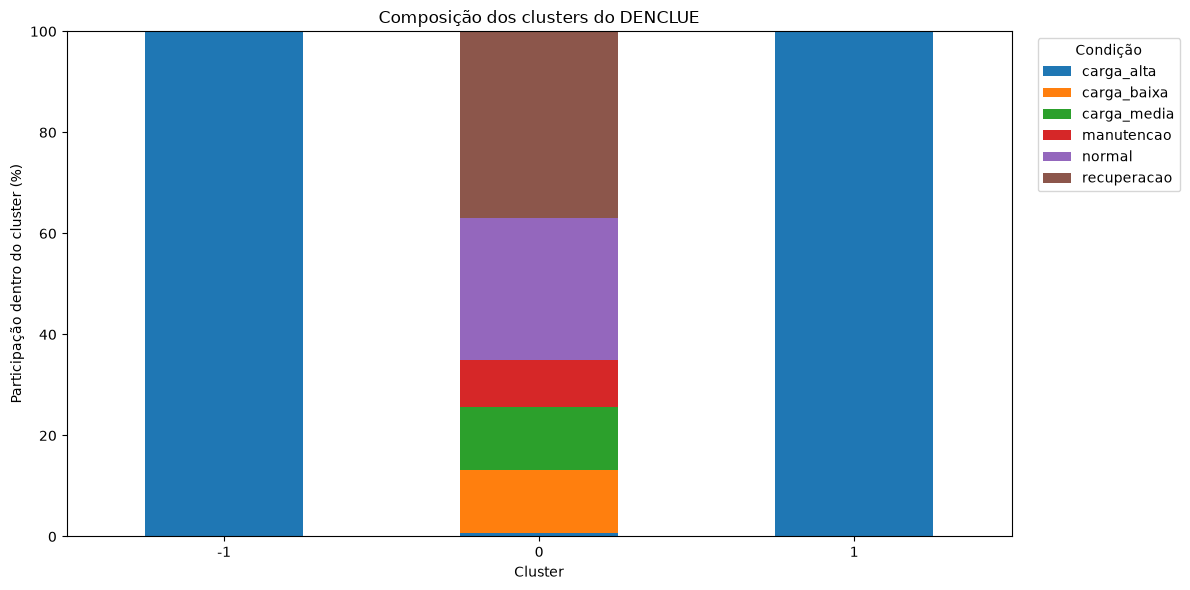

In [80]:
composicao_denclue.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title(
    "Composição dos clusters do DENCLUE"
)

plt.xlabel(
    "Cluster"
)

plt.ylabel(
    "Participação dentro do cluster (%)"
)

plt.legend(
    title="Condição",
    bbox_to_anchor=(1.02, 1)
)

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()